# Lab 11: Model Optimization and Deployment
**ITAI 1378 Computer Vision | Houston City College | AI and Robotics Program**
**Module 11: Model Optimization and Deployment | Instructor: Patricia McManus**

> **Bonus lab (optional).** After Module 08, every lab in ITAI 1378 is a **bonus** lab. It is not mandatory, and skipping it will not lower your grade. Completing it earns bonus credit.

Welcome to the last lab of the course! A model that works in a notebook is not yet a service. In this lab you will do the two halves of Module 11 on a plain CPU, with no GPU, Docker, paid API, or public endpoint needed:

**Half A: one optimization change, measured fairly.** You run a pinned YOLO detector at input size 640 (the baseline), then change **only** the input size to 320 (the candidate). You warm up, time at least 100 calls per condition, and record the median, the p95, missed objects, and false positives on a small labeled image set.

**Half B: a small, testable detection API.** You wrap the detector in a FastAPI service with an explicit contract (`POST /v1/detections`), test it with valid and invalid images, then switch configurations and **prove a rollback** to the baseline.

Keeping the baseline is a valid decision. If the smaller input size is not worth it for your task, say so and explain why.

**Before you start:** File > Save a copy in Drive, then rename your copy `Lab_11_LastName_FirstName_ITAI1378.ipynb`. Runtime > Run all on the free CPU runtime takes about 5 to 10 minutes.

## Part 1: Setup

In [1]:
%pip install -q ultralytics opencv-python-headless fastapi python-multipart httpx

In [2]:
import os, io, json, time, glob, hashlib, platform, zipfile, urllib.request
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, ultralytics, fastapi
from ultralytics import YOLO

torch.set_num_threads(max(1, os.cpu_count() or 1))
WEIGHTS = "yolov8n.pt"            # the pinned model for this lab
model = YOLO(WEIGHTS)

def sha256(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

MODEL_VERSION = "yolov8n-" + sha256(WEIGHTS)[:12]   # a checksum based version label
print("Model version:", MODEL_VERSION)
print("Weight file size:", round(os.path.getsize(WEIGHTS) / 1e6, 2), "MB")
print("Versions | ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| fastapi", fastapi.__version__)
print("CPU:", platform.processor() or platform.machine(), "|", os.cpu_count(), "cores")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model version: yolov8n-f59b3d833e2f
Weight file size: 6.55 MB
Versions | ultralytics 8.4.215 | torch 2.14.1+cpu | fastapi 0.141.1
CPU: x86_64 | 2 cores


## Part 2: The labeled image set
We use **COCO8**, a tiny public set of 8 images with reference labels, published by Ultralytics for testing. Each label file lists the class and box of every reference object. This is small classroom evidence, not a full benchmark.

The helpers below are provided. `match` pairs each reference object with at most one prediction of the same class whose boxes overlap enough (IoU of at least 0.5).

In [3]:
if not os.path.exists("coco8"):
    urllib.request.urlretrieve("https://github.com/ultralytics/assets/releases/download/v0.0.0/coco8.zip", "coco8.zip")
    zipfile.ZipFile("coco8.zip").extractall(".")

IMAGE_PATHS = sorted(glob.glob("coco8/images/*/*.jpg"))
IMAGES = [cv2.imread(p) for p in IMAGE_PATHS]          # loaded once, before timing

def load_refs(img_path, img):
    h, w = img.shape[:2]
    lab = img_path.replace("images", "labels").replace(".jpg", ".txt")
    refs = []
    for line in open(lab):
        c, cx, cy, bw, bh = map(float, line.split())
        refs.append({"cls": int(c), "box": ((cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h)})
    return refs

REFS = [load_refs(p, im) for p, im in zip(IMAGE_PATHS, IMAGES)]
print(len(IMAGES), "images,", sum(len(r) for r in REFS), "reference objects")

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union else 0.0

def match(refs, preds, thr=0.5):
    """Greedy matching. Returns the number of matched pairs."""
    used, matched = set(), 0
    for r in refs:
        best, best_j = 0, None
        for j, p in enumerate(preds):
            if j in used or p["cls"] != r["cls"]:
                continue
            v = iou(r["box"], p["box"])
            if v > best:
                best, best_j = v, j
        if best_j is not None and best >= thr:
            used.add(best_j); matched += 1
    return matched

8 images, 30 reference objects


## Part 3: A fair benchmark
Settings that stay **fixed** in both conditions: the same weights, images, confidence threshold, `device="cpu"`, `batch=1`, `rect=False`. The **only** change is `imgsz`.

**Timing boundary:** we time the `model.predict` call on images that are already loaded. That includes preprocessing, inference, and postprocessing. It excludes model loading, disk reads, network transfer, and drawing. Each condition is **warmed up** first, because the first calls are slow for reasons that have nothing to do with the model.

### TODO 1: Summarize the timings
Finish `summarize_times` so it returns the median, the 95th percentile (p95), and the number of timed calls. Use `np.median` and `np.percentile(times_ms, 95)`.

In [6]:
# Keep these baseline settings fixed, except for input size in the candidate.
BASELINE = {"config_id": "cfg-640", "imgsz": 640, "conf": 0.25, "device": "cpu", "batch": 1, "rect": False}

# Run one prediction with the settings from the selected configuration.
def predict(img, cfg):
    return model.predict(img, imgsz=cfg["imgsz"], conf=cfg["conf"], device=cfg["device"],
                         batch=cfg["batch"], rect=cfg["rect"], verbose=False)[0]

# Report typical latency, slower calls (p95), and total timed calls.
def summarize_times(times_ms):
    # Summarize all timed calls after the warm-up runs.
    return {
        "median_ms": float(np.median(times_ms)),
        "p95_ms": float(np.percentile(times_ms, 95)),
        "count": len(times_ms),
    }

# Warm up first, then time 104 predictions without including image loading.
def benchmark(cfg, repeats=13, warmup=10):
    for i in range(warmup):                         # warm up, not timed
        predict(IMAGES[i % len(IMAGES)], cfg)
    times = []
    for _ in range(repeats):                        # 13 x 8 images = 104 timed calls
        for img in IMAGES:
            t0 = time.perf_counter()
            predict(img, cfg)
            times.append((time.perf_counter() - t0) * 1000)
    return times

base_times = benchmark(BASELINE)
print("Baseline (640):", summarize_times(base_times))

Baseline (640): {'median_ms': 245.49851699998726, 'p95_ms': 575.8409555501086, 'count': 104}


### TODO 2: Define the candidate with exactly one change
Make `CANDIDATE` a copy of `BASELINE` with `imgsz` set to **320** and `config_id` set to `"cfg-320"`. The check below confirms that only the input size changed (the id is just a label).

Settings changed: {'imgsz'}
Candidate: {'median_ms': 79.81202350003969, 'p95_ms': 173.78008374990938, 'count': 104}


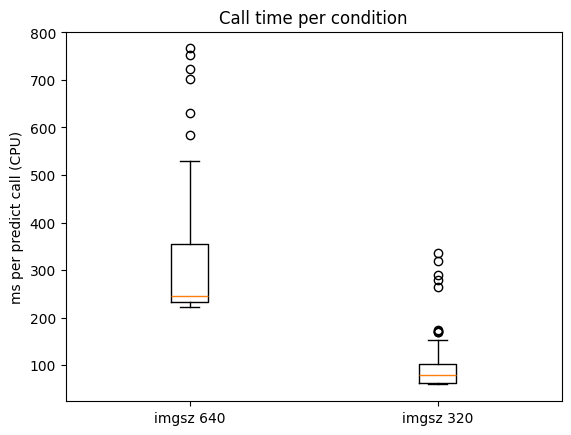

In [7]:
# Copy the baseline so input size is the only model setting that changes.
CANDIDATE = dict(BASELINE)
CANDIDATE["imgsz"] = 320
CANDIDATE["config_id"] = "cfg-320"

# Check that the candidate changed only imgsz, not confidence or device.
changed = {k for k in BASELINE if BASELINE[k] != CANDIDATE[k]} - {"config_id"}
print("Settings changed:", changed if changed else "none yet (TODO 2)")
assert changed <= {"imgsz"}, "Change only the input size."

# Time the 320-pixel candidate and compare its latency with the baseline.
cand_times = benchmark(CANDIDATE)
print("Candidate:", summarize_times(cand_times))

plt.boxplot([base_times, cand_times])
plt.xticks([1, 2], [f"imgsz {BASELINE['imgsz']}", f"imgsz {CANDIDATE['imgsz']}"])
plt.ylabel("ms per predict call (CPU)"); plt.title("Call time per condition"); plt.show()

## Part 4: Did quality change?
Speed is only half the story. A smaller input means small objects have fewer pixels, so some may be missed.

### TODO 3: Count misses and false positives
For each image, `n_matched` pairs were found. Finish the two lines so that:
- **misses** = reference objects with no matching prediction
- **false positives** = predictions that did not match any reference object

In [8]:
# Compare each image against its reference labels at the same IoU threshold.
def quality(cfg):
    rows = []
    for path, img, refs in zip(IMAGE_PATHS, IMAGES, REFS):
        r = predict(img, cfg)
        preds = [{"cls": int(c), "box": tuple(b)} for c, b in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
        # Unmatched reference objects are misses; extra predictions are false positives.
        n_matched = match(refs, preds)
        misses = len(refs) - n_matched
        false_pos = len(preds) - n_matched
        rows.append({"image": os.path.basename(path), "refs": len(refs), "preds": len(preds),
                     "misses": misses, "false_pos": false_pos})
    return pd.DataFrame(rows)

# Run both sizes on the same images before making the side-by-side table.
q_base, q_cand = quality(BASELINE), quality(CANDIDATE)
paired = q_base.merge(q_cand, on=["image", "refs"], suffixes=("_640", "_cand"))
paired

,image,refs,preds_640,misses_640,false_pos_640,preds_cand,misses_cand,false_pos_cand
0,000000000009.jpg,8,5,4,1,5,4,1
1,000000000025.jpg,2,1,1,0,1,1,0
2,000000000030.jpg,2,2,0,0,2,0,0
3,000000000034.jpg,1,1,0,0,1,0,0
4,000000000036.jpg,2,2,0,0,3,0,1
5,000000000042.jpg,1,3,0,2,1,1,1
6,000000000049.jpg,9,8,3,2,6,7,4
7,000000000061.jpg,5,2,3,0,0,5,0


### The lab record

In [9]:
record = pd.DataFrame([
    {"condition": f"baseline imgsz {BASELINE['imgsz']}", **summarize_times(base_times),
     "misses": int(q_base.misses.sum()), "false_pos": int(q_base.false_pos.sum()),
     "weights_MB": round(os.path.getsize(WEIGHTS) / 1e6, 2)},
    {"condition": f"candidate imgsz {CANDIDATE['imgsz']}", **summarize_times(cand_times),
     "misses": int(q_cand.misses.sum()), "false_pos": int(q_cand.false_pos.sum()),
     "weights_MB": round(os.path.getsize(WEIGHTS) / 1e6, 2)},
])
record

,condition,median_ms,p95_ms,count,misses,false_pos,weights_MB
0,baseline imgsz 640,245.498517,575.840956,104,11,5,6.55
1,candidate imgsz 320,79.812024,173.780084,104,18,7,6.55


Look at one image where the two conditions disagree (change `IMAGE_INDEX` if you like).

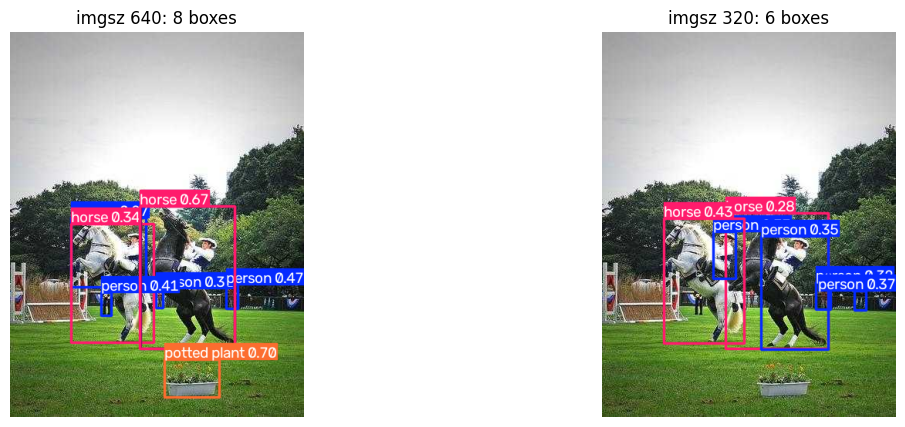

In [10]:
IMAGE_INDEX = int(np.argmax((paired.misses_cand - paired.misses_640).abs().values))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cfg in zip(axes, [BASELINE, CANDIDATE]):
    r = predict(IMAGES[IMAGE_INDEX], cfg)
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"imgsz {cfg['imgsz']}: {len(r.boxes)} boxes")
plt.show()

**Reflection 1 (measurement):** Report your median and p95 for both conditions. Why do we warm up before timing, and why do we exclude model loading and disk reads? Why are 104 repeated timings on 8 images **not** 104 independent quality examples?

*Your answer:*

- My baseline with an image size of 640 had a median processing time of 245.5 ms and a p95 of 575.8 ms. After changing the image size to 320, the median dropped to 79.8 ms and the p95 to 173.8 ms. Both conditions had 104 timing measurements. We warm up the model before timing because the first predictions may take longer while the model prepares everything. We exclude model loading and disk reads to focus on prediction speed and make the comparison fair. Although I recorded 104 measurements, I only used 8 different images. This means I tested the same images multiple times rather than testing 104 independent examples. The repeated measurements help compare processing times, but they don't tell us how well the model handles completely new images.

**Reflection 2 (decision):** Did the weight file size change? Why not? Based on your record, would you ship 320 or keep 640 for (a) a parking lot car counter and (b) a system that must spot small items on a shelf? Keeping the baseline is a valid answer if you explain it.

*Your answer:*

- The weight file stayed the same at 6.55 MB because I only changed the input image size, not the model itself. The smaller size made predictions much faster, but it also increased missed objects from 11 to 18 and false positives from 5 to 7. In the example image, the baseline detected 8 objects, while the smaller version found only 6. For a parking lot car counter, I would consider using 320 because faster processing could help the system handle more frames. However, I would test it on more videos first because missed detections could affect the counts. For detecting small items on a shelf, I would keep 640 because reducing the image size could make those objects harder to recognize. In that situation, accuracy matters more than speed.

## Part 5: Other optimization tools (read, then optional)
Input size is the easiest change, but it is not the only one. From the Module 11 booklet:
- **Quantization** stores weights with fewer bits (for example INT8 instead of FP32, about 75 percent smaller). That number does not promise a 75 percent speedup; it depends on hardware and runtime support. Accuracy must be checked again.
- **Pruning** removes weights or whole channels. Zeros only save time if the runtime can skip them.
- **Knowledge distillation** trains a small "student" model to copy a big "teacher". The teacher does not ship.
- **Exporting** to a runtime format such as **ONNX** can change speed, and it can also introduce bugs (wrong preprocessing, wrong class order). **Always validate after conversion.**

**Optional (not graded):** set `RUN_OPTIONAL_EXPORT = True` to export the model to ONNX and compare file sizes. It installs extra packages and takes a few minutes.

In [11]:
import sys
import subprocess

# Test both settings: False first, then True.
for RUN_OPTIONAL_EXPORT in [False, True]:
    print(f"\nRUN_OPTIONAL_EXPORT = {RUN_OPTIONAL_EXPORT}")

    if RUN_OPTIONAL_EXPORT:
        # Install the packages needed for ONNX export.
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            "-q", "onnx", "onnxruntime", "onnxslim"
        ])

        # Export the model using the 320 image size.
        onnx_path = model.export(format="onnx", imgsz=320)

        # Compare PyTorch and ONNX file sizes.
        print("PyTorch weights:",
              round(os.path.getsize(WEIGHTS) / 1e6, 2), "MB")
        print("ONNX:",
              round(os.path.getsize(onnx_path) / 1e6, 2), "MB")

        # Load the exported ONNX model.
        onnx_model = YOLO(onnx_path)

        # Run the same image through both models.
        onnx_result = onnx_model.predict(
            IMAGES[0], imgsz=320, device="cpu", verbose=False
        )[0]

        pytorch_result = predict(
            IMAGES[0], {**BASELINE, "imgsz": 320}
        )

        # Compare the number of detected objects.
        print("ONNX boxes on image 0:", len(onnx_result.boxes))
        print("PyTorch boxes at 320:", len(pytorch_result.boxes))

    else:
        # Skip the optional export.
        print("Optional export skipped.")


RUN_OPTIONAL_EXPORT = False
Optional export skipped.

RUN_OPTIONAL_EXPORT = True
Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 2.2 GFLOPs

PyTorch: starting from 'yolov8n.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 84, 2100) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.2s, saved as 'yolov8n.onnx' (12.1 MB)

Export complete (3.5s)
Results saved to /content/yolov8n.onnx
Predict:         yolo predict task=detect model=yolov8n.onnx imgsz=320 
Validate:        yolo val task=detect model=yolov8n.onnx imgsz=320 data=coco.yaml 
Visualize:       https://netron.app
PyTorch weights: 6.55 MB
ONNX: 12.73 MB
Loading yolov8n.onnx for ONNX Runtime infer

**Reflection 3 (optimization tools):** Pick quantization, pruning, or distillation. In two or three sentences, explain what it changes and one thing you must check before you trust the optimized model.

*Your answer:*

- I would choose quantization because it reduces the precision of the numbers a model uses, which can make the model smaller and help it run faster. However, lower precision might affect how accurately the model detects objects, especially smaller ones. Before trusting the optimized model, I would test it on the same labeled images as the original and compare its missed detections, false positives, and processing times to see whether the speed improvement is worth any loss in accuracy.

## Part 6: A detection API with an explicit contract
**The contract**
- `POST /v1/detections` with a multipart image upload named `file`.
- **200** response: `{"model_version", "config_id", "imgsz", "detections": [{"label", "conf", "box": [x1, y1, x2, y2]}]}`
- **400** response when the upload is not a decodable image: `{"detail": "..."}`
- `GET /health` returns whether the model is loaded (ready), plus the active version and config.

The app reads its active configuration from `active_config.json` when it starts. That is how we will switch to the candidate and roll back. We write the app to a file, the same way you would package it for a container.

### TODO 4: Validate before inference
In `detect`, `cv2.imdecode` returns `None` when the bytes are not an image. Add a check that raises `HTTPException(status_code=400, detail="Upload is not a decodable image")` in that case.

In [14]:
# Store the FastAPI service code and save it as a Python module.
APP_CODE = '''
import json, cv2, numpy as np
from contextlib import asynccontextmanager
from fastapi import FastAPI, File, UploadFile, HTTPException
from ultralytics import YOLO

# Keep the model in memory while the API is running.
STATE = {}

@asynccontextmanager
async def lifespan(app):
    with open("active_config.json") as f:
        STATE["cfg"] = json.load(f)
    STATE["model"] = YOLO(STATE["cfg"]["weights"])     # load once, at startup
    yield
    STATE.clear()

app = FastAPI(title="Detection API", lifespan=lifespan)

# The health endpoint reports which configuration the service has loaded.
@app.get("/health")
def health():
    cfg = STATE.get("cfg", {})
    return {"ready": "model" in STATE, "model_version": cfg.get("model_version"),
            "config_id": cfg.get("config_id"), "imgsz": cfg.get("imgsz")}

# The detection endpoint accepts image uploads and returns boxes with scores.
@app.post("/v1/detections")
async def detect(file: UploadFile = File(...)):
    data = await file.read()
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    # Reject files that OpenCV cannot decode instead of calling the detector.
    if img is None:
        raise HTTPException(status_code=400, detail="Upload is not a decodable image")

    cfg, model = STATE["cfg"], STATE["model"]
    r = model.predict(img, imgsz=cfg["imgsz"], conf=cfg["conf"], device="cpu", verbose=False)[0]
    dets = [{"label": model.names[int(c)], "conf": round(float(p), 3), "box": [round(v, 1) for v in b]}
            for c, p, b in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]
    return {"model_version": cfg["model_version"], "config_id": cfg["config_id"],
            "imgsz": cfg["imgsz"], "detections": dets}
'''
with open("detection_api.py", "w") as f:
    f.write(APP_CODE)

# Save the active settings so the service can reload a release or rollback.
def write_active_config(cfg):
    with open("active_config.json", "w") as f:
        json.dump({**cfg, "weights": WEIGHTS, "model_version": MODEL_VERSION}, f, indent=2)

write_active_config(BASELINE)
print(open("active_config.json").read())

{
  "config_id": "cfg-640",
  "imgsz": 640,
  "conf": 0.25,
  "device": "cpu",
  "batch": 1,
  "rect": false,
  "weights": "yolov8n.pt",
  "model_version": "yolov8n-f59b3d833e2f"
}


### Test the API in process
FastAPI's `TestClient` runs the app inside the notebook without a network socket. Using it as a context manager (`with TestClient(app) as client:`) makes the startup code run, so the model is loaded. It is great for checking **behavior**. It does **not** measure network latency or load capacity.

The fixtures: `valid_upload` is a real JPEG, `bad_upload` is text pretending to be an image.

In [15]:
import importlib, detection_api
from fastapi.testclient import TestClient

ok, buf = cv2.imencode(".jpg", IMAGES[0])
valid_upload = ("valid.jpg", buf.tobytes(), "image/jpeg")
bad_upload = ("bad.jpg", b"this is not an image", "image/jpeg")

def fresh_client():
    importlib.reload(detection_api)                 # like restarting the service
    return TestClient(detection_api.app, raise_server_exceptions=False)

def check(name, condition):
    print(("PASS " if condition else "FAIL ") + name)
    return condition

with fresh_client() as client:
    print("health:", client.get("/health").json())
    resp = client.post("/v1/detections", files={"file": valid_upload})
    body = resp.json()
    check("valid image returns 200", resp.status_code == 200)
    check("response has the expected model_version", body.get("model_version") == MODEL_VERSION)
    check("response has a detections list", isinstance(body.get("detections"), list))
    BASELINE_EXPECTED = body                         # the known answer for the rollback check
    print("first detections:", body.get("detections", [])[:3])

health: {'ready': True, 'model_version': 'yolov8n-f59b3d833e2f', 'config_id': 'cfg-640', 'imgsz': 640}
PASS valid image returns 200
PASS response has the expected model_version
PASS response has a detections list
first detections: [{'label': 'bowl', 'conf': 0.916, 'box': [308.6, 0.4, 626.2, 238.9]}, {'label': 'broccoli', 'conf': 0.672, 'box': [254.2, 233.6, 566.6, 478.8]}, {'label': 'bowl', 'conf': 0.553, 'box': [0.0, 8.1, 452.5, 460.2]}]


### TODO 5: Test the invalid upload
Post `bad_upload` and check that the status code is **400** and that the JSON has a `detail` field. Before TODO 4 is done this test should FAIL, which is exactly what a test is for.

In [16]:
# A non-image file should return HTTP 400 with a helpful error message.
with fresh_client() as client:
    resp = client.post("/v1/detections", files={"file": bad_upload})
    check("bad image returns 400", resp.status_code == 400)
    check("error has a detail message", "detail" in resp.json())

PASS bad image returns 400
PASS error has a detail message


## Part 7: Switch to the candidate, then prove the rollback
A rollback you never rehearsed is a hope, not a plan. We switch the service to the candidate configuration, confirm it is active, then restore the baseline and verify it.

Notice that `model_version` is the **same** in both configurations, because the weights did not change. Only `config_id` and `imgsz` can tell them apart.

### TODO 6: Verify the rollback
After restoring the baseline, check that (a) `config_id` equals `BASELINE["config_id"]`, (b) `imgsz` is 640, and (c) the known image gives the same number of detections as `BASELINE_EXPECTED`.

In [17]:
# Switch to the smaller candidate and confirm it becomes active.
write_active_config(CANDIDATE)                     # release the candidate
with fresh_client() as client:
    h = client.get("/health").json()
    print("after switch:", h)
    cand_body = client.post("/v1/detections", files={"file": valid_upload}).json()
    print("candidate detections on the known image:", len(cand_body.get("detections", [])))

# Restore the baseline and check that its settings and known result return.
write_active_config(BASELINE)                      # roll back
with fresh_client() as client:
    h = client.get("/health").json()
    body = client.post("/v1/detections", files={"file": valid_upload}).json()
    print("after rollback:", h)
    check("config_id is the baseline", h["config_id"] == BASELINE["config_id"])
    check("imgsz is 640", h["imgsz"] == 640)
    check("same detection count as before", len(body["detections"]) == len(BASELINE_EXPECTED["detections"]))

after switch: {'ready': True, 'model_version': 'yolov8n-f59b3d833e2f', 'config_id': 'cfg-320', 'imgsz': 320}
candidate detections on the known image: 4
after rollback: {'ready': True, 'model_version': 'yolov8n-f59b3d833e2f', 'config_id': 'cfg-640', 'imgsz': 640}
PASS config_id is the baseline
PASS imgsz is 640
PASS same detection count as before


**Reflection 4 (API and tests):** What does the 400 response protect the service from? Name one thing TestClient **cannot** tell you about how this API would behave in production.

*Your answer:*

- The 400 response helps protect the service from invalid files that the model cannot process. In my test, the API correctly rejected a bad image and returned an error message explaining the problem. This is important because users might accidentally upload the wrong file type or send damaged images. Instead of trying to process those files, the service can explain what went wrong. However, TestClient cannot show how the API would perform under real conditions with many users sending requests at the same time. It doesn't fully test network delays, server performance, or heavy traffic. Before using this API in production, I would test how it handles multiple requests and whether it stays reliable.

**Reflection 5 (rollback):** Why can `model_version` alone not tell the baseline and candidate apart? What else belongs in a model release bundle besides the weight file (think class names, preprocessing, thresholds, versions)?

*Your answer:*

- The model_version alone cannot tell the baseline and candidate apart because both configurations use the same YOLO weights. In my test, I changed the image size from 640 to 320, but the model version stayed the same. This is why the configuration ID matters. After switching back to the baseline, all three rollback checks passed. The API returned the original configuration ID, restored the image size to 640, and produced the same detection count as before. I think a model release should include more than just the weight file. It should contain the class names, preprocessing steps, confidence thresholds, configuration settings, package versions, and test results. These details help make sure the system behaves consistently after deployment or rollback.

## Part 8: Wrap-up questions
Answer each in about 75 to 150 words, in your own words.

1. **A defensible deployment decision:** Using your lab record, write a short recommendation to a manager: ship the candidate, keep the baseline, or test more. Include your numbers and their limits.

 - Based on my results, I would recommend testing the candidate more before replacing the baseline. Changing the image size from 640 to 320 reduced the median processing time from 245.5 ms to 79.8 ms, which is a big improvement. However, the smaller image size increased missed detections from 11 to 18 and false positives from 5 to 7. This means the faster version could overlook more objects or detect things incorrectly. I think the candidate could work well in situations where speed matters more, but I wouldn't recommend it for tasks that require accurate detection of small objects. My test only included 8 different images, so I would need more examples and real-world testing before making a final decision.

2. **Where it runs:** Would you run this detector in the cloud, on an edge device next to the camera, or on premises? Give two requirements that drive your choice (latency, cost, privacy, connectivity).

- I would choose an edge device near the camera because it could process video without constantly sending everything to the cloud. My two main concerns would be latency and privacy. For a monitoring system, quick responses matter, especially when the camera needs to detect something important. Processing images locally could reduce network delays and allow the system to continue working even if the internet connection becomes unstable. It could also protect privacy because the device wouldn't need to send every video frame to an outside server. However, I would first check whether the edge device has enough processing power. My candidate still had a p95 of 173.8 ms, so I would need to test its performance on the actual hardware before choosing this setup.

3. **Releases and safety:** Explain how a shadow or canary release could reduce the risk of switching to a new configuration, and name one security or data handling control you would add to the API.

- I think a shadow release would be a good way to test a new model configuration without immediately affecting the current system. Both versions could process the same images, but only the existing version would provide the official results. This would let me compare their predictions and look for unexpected problems before making the switch. A canary release could help too because I could introduce the new configuration to a small number of users first. If something went wrong, I could return to the previous version, just like I tested in this lab. For security, I would add a file size limit to the API. This would help prevent users from uploading extremely large files that could overload the service.

---
**Submit:** Runtime > Restart session and run all. Then File > Download > Download .ipynb and upload `Lab_11_LastName_FirstName_ITAI1378.ipynb` to the Lab 11 (Bonus) assignment in Canvas. Make sure the record table, PASS lines, and plots are visible.

If you used an AI assistant to help with an error or a concept, add one sentence at the end saying what you used it for.

**AI usage note:** I used ChatGPT to help with Python code and troubleshooting.